<a href="https://colab.research.google.com/github/nikistendo/Niki-Tendolkar-Maker-Portfolio/blob/main/Leukemia_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import cv2 as cv

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
img = cv.imread('/content/drive/MyDrive/Leukemia_Image.jpg', cv.IMREAD_GRAYSCALE)

img = cv.medianBlur(img, 5)

In [ ]:
# Apply MedianBlur with kernel size 5x5
cimg = cv.cvtColor(img,cv.COLOR_GRAY2BGR)

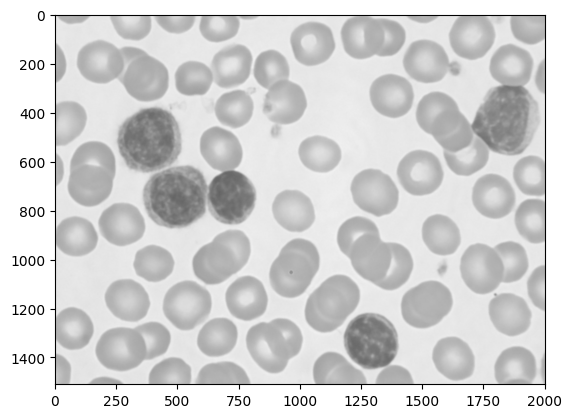

In [ ]:
plt.imshow(cimg)

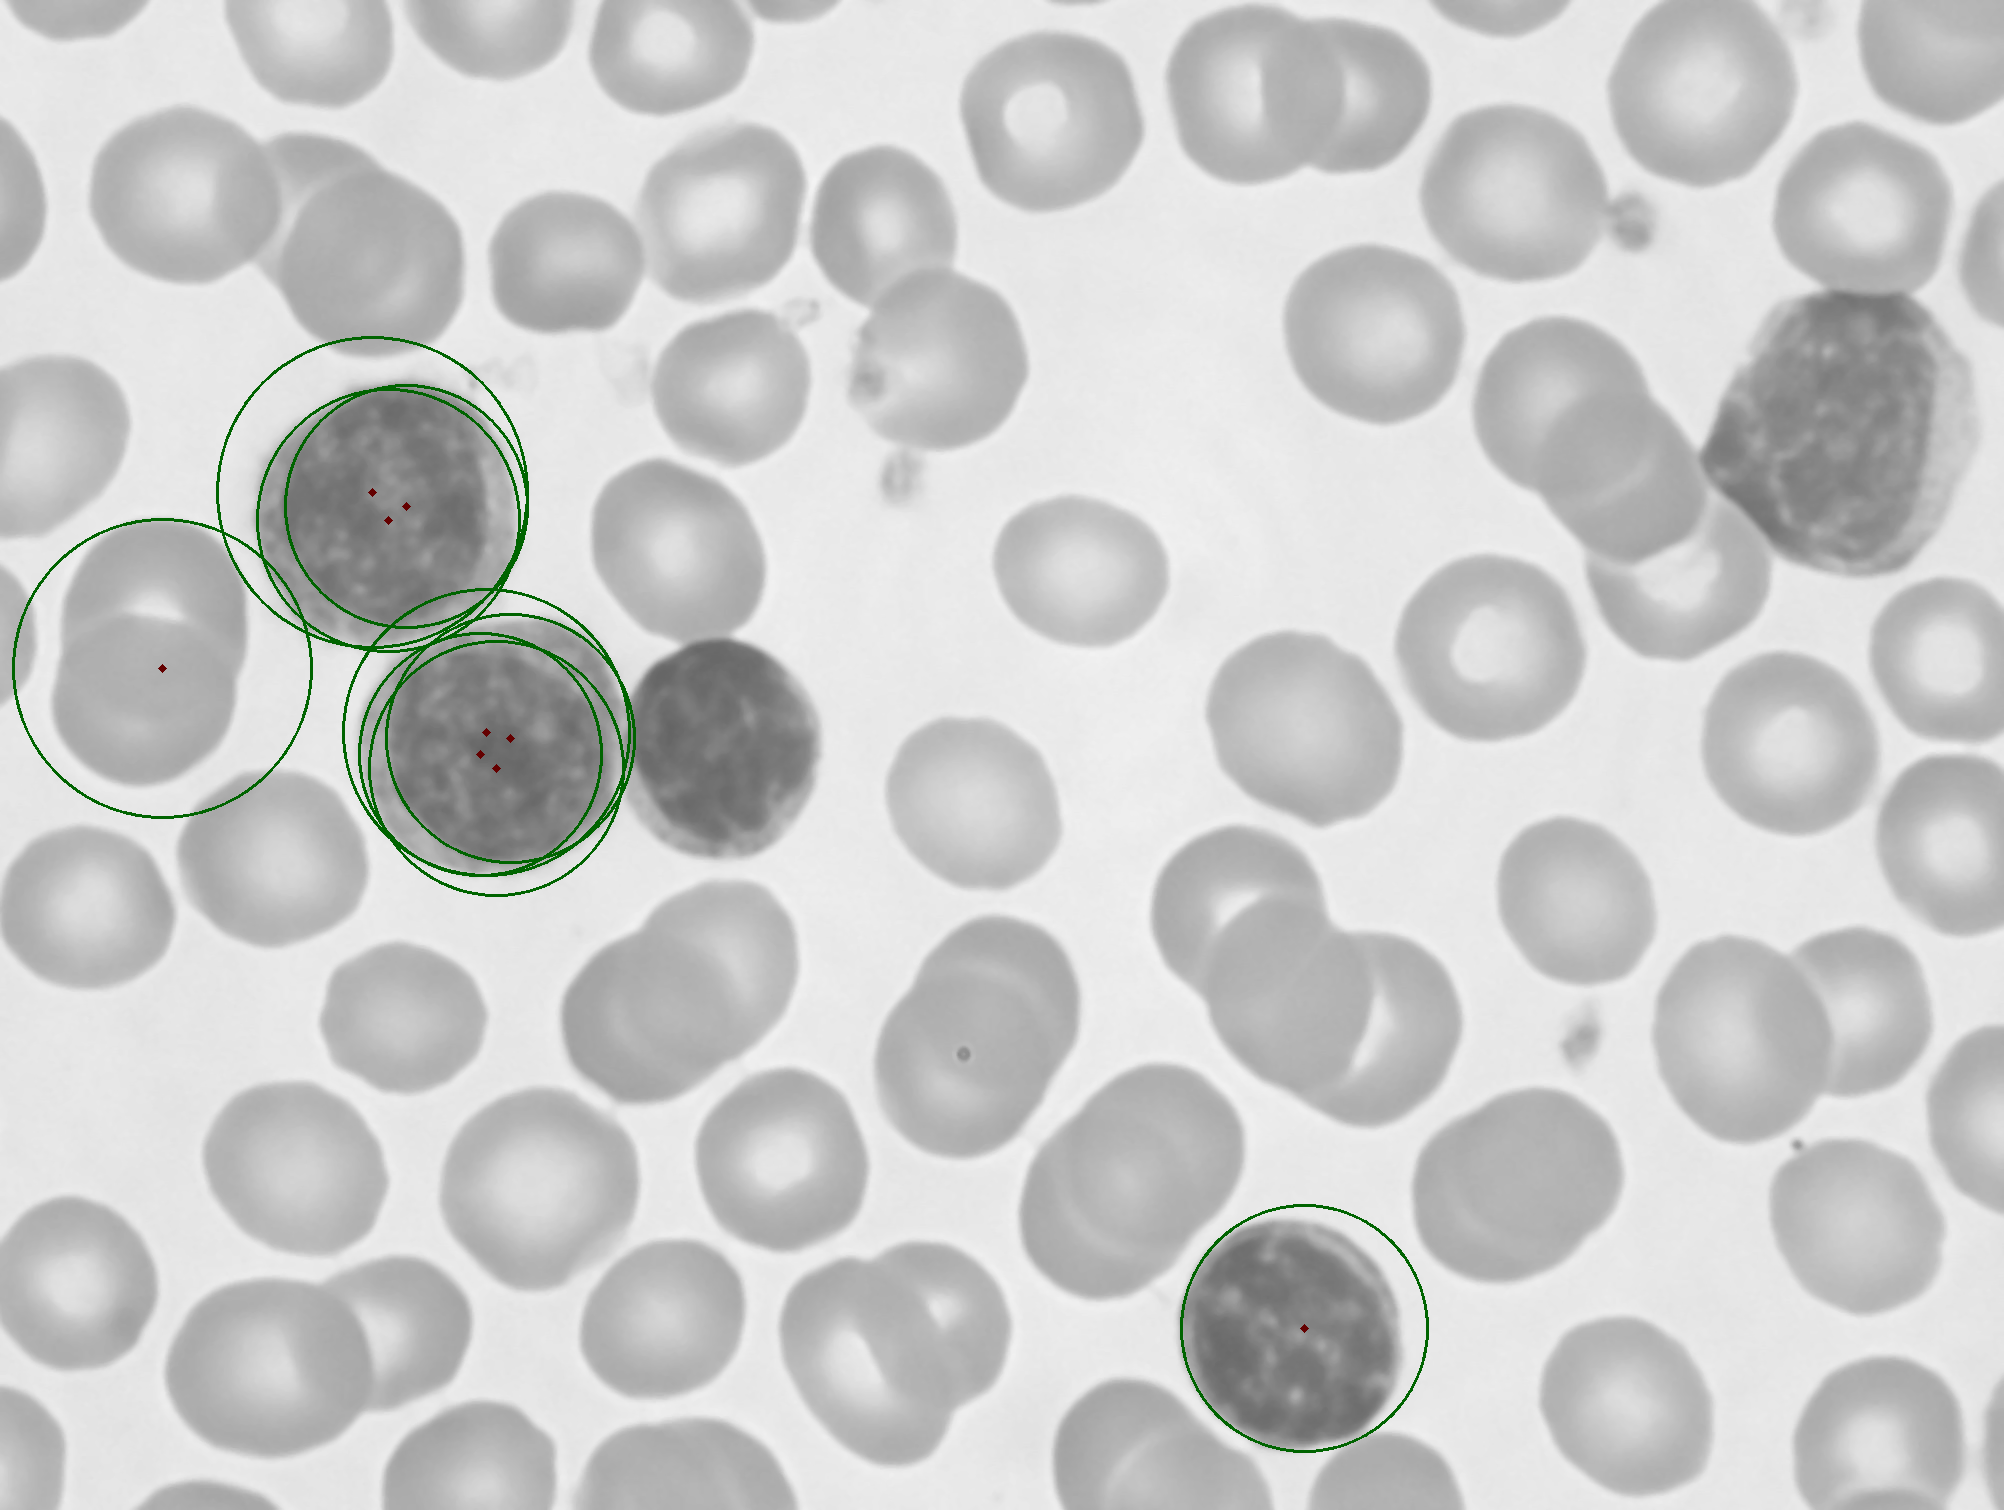

In [ ]:
# apply method on grayscale, blurred image with circles of radius between 40-100 pixels
circles = cv.HoughCircles(img,cv.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=120, maxRadius=250)
# for each detected circle, draw larger circle and apply to new image
circles = np.uint16(np.around(circles))
for  i in circles[0,:]:
  # draw the outer circle
  cv.circle(cimg,(i[0],i[1]),i[2],(0,100,0),2)
  # draw the center of the circle
  cv.circle(cimg,(i[0],i[1]),2,(0,0,100),3)
from google.colab.patches import cv2_imshow
cv2_imshow(cimg)

In [ ]:
import cv2

In [ ]:
image = cv.imread('/content/drive/MyDrive/Leukemia_Image.jpg')
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

In [ ]:
lower_purple=np.array([120, 50, 50])
upper_purple=np.array([150, 255, 255])

In [ ]:
# construct a mask which only captures purple pixels within this range
mask = cv2.inRange(hsv, lower_purple, upper_purple)

In [ ]:
# find contours (boundaries) of the purple regions and store in list
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# create an output image with only the purple cells
output = np.zeros_like(image)
# apply contours and make the regions white for all indices of contours list
for cnt in contours:
  cv2.drawContours(output, [cnt], -1, (255, 255, 255), thickness=cv2.FILLED)
  #apply the mask on white  (255) pixels to only show purple regions
extracted_cells = cv2.bitwise_and(image, image, mask=mask)

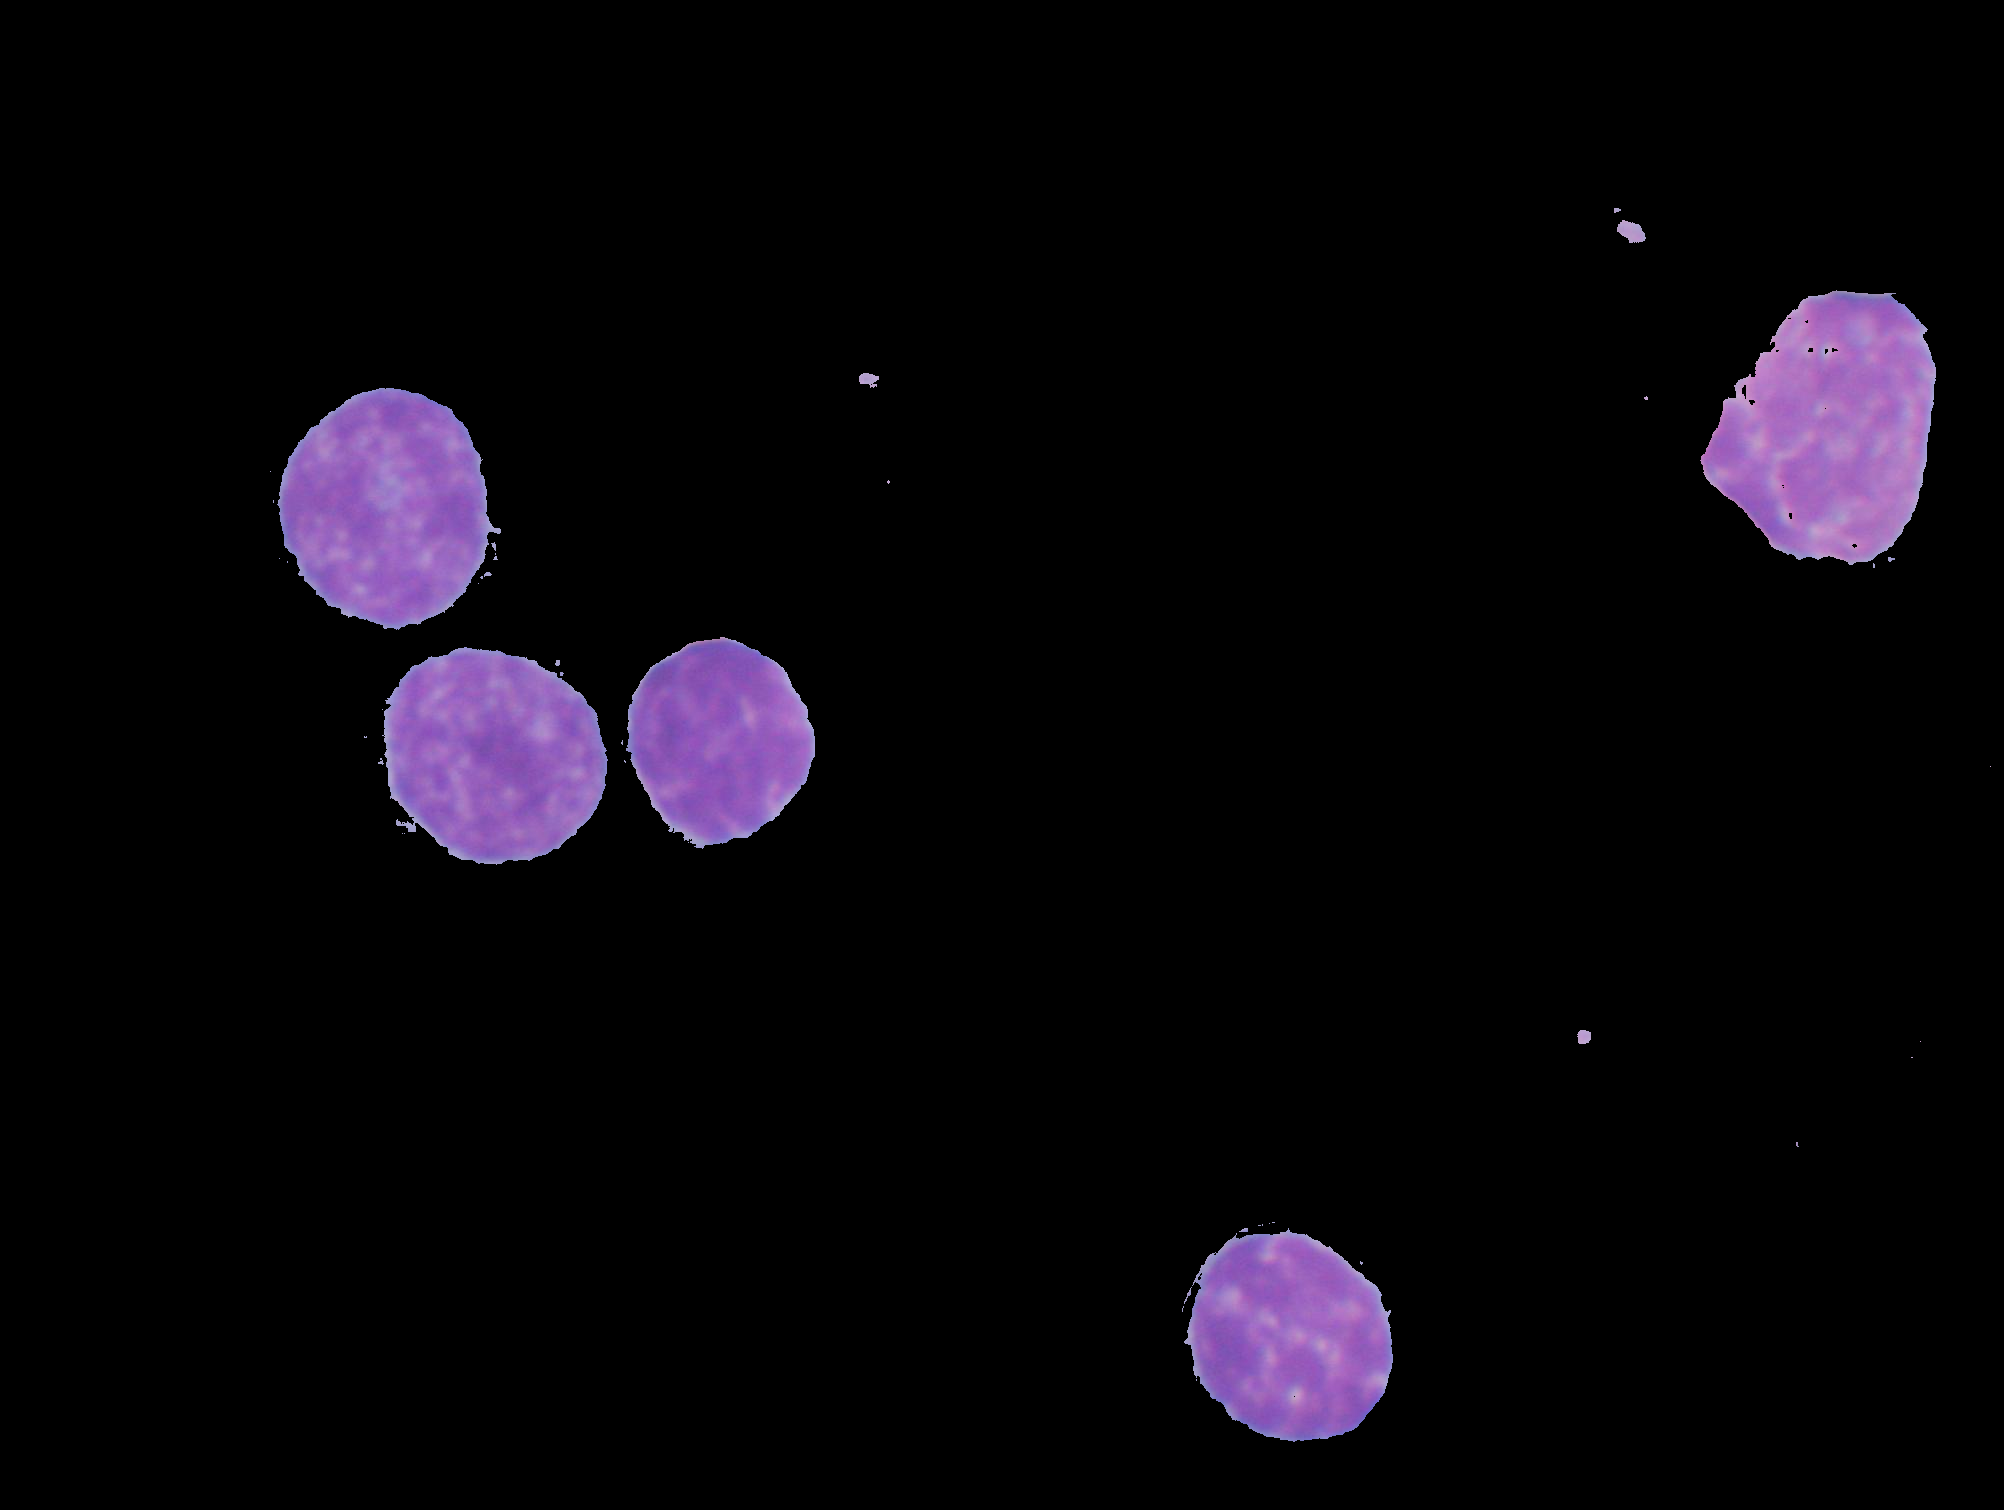

In [ ]:
from google.colab.patches import cv2_imshow
cv2_imshow(extracted_cells)

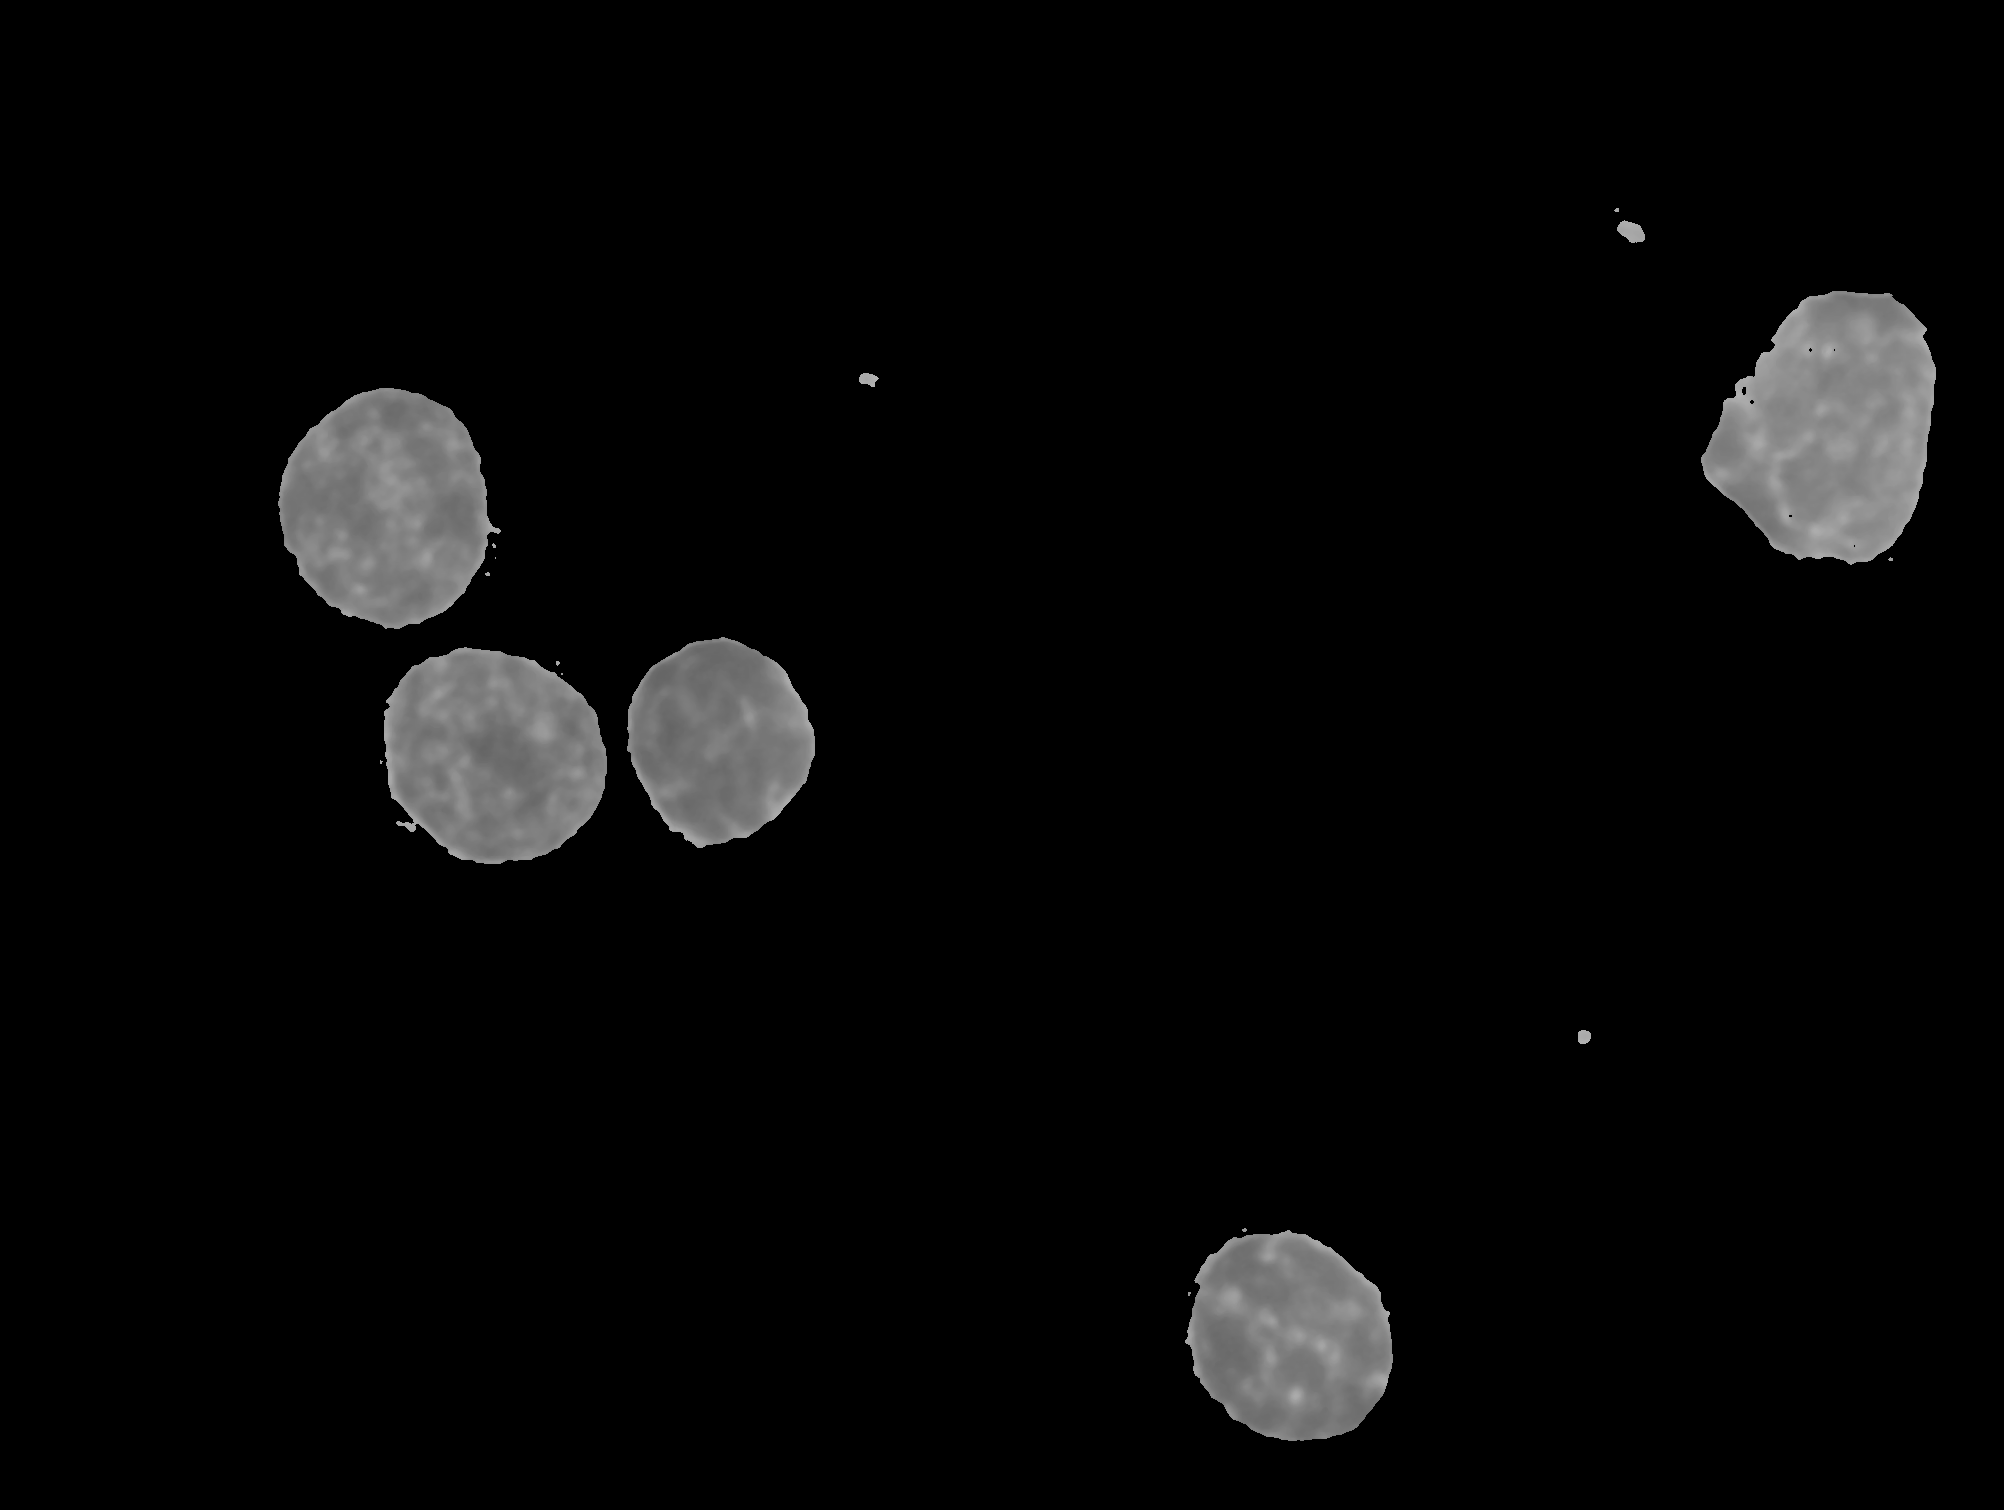

In [ ]:
gray_cells = cv2.cvtColor(extracted_cells, cv2.COLOR_BGR2GRAY)

gray_cells = cv2.medianBlur(gray_cells, 5)
cv2_imshow(gray_cells)

In [ ]:
cimg = cv2.cvtColor(gray_cells,cv.COLOR_GRAY2BGR)

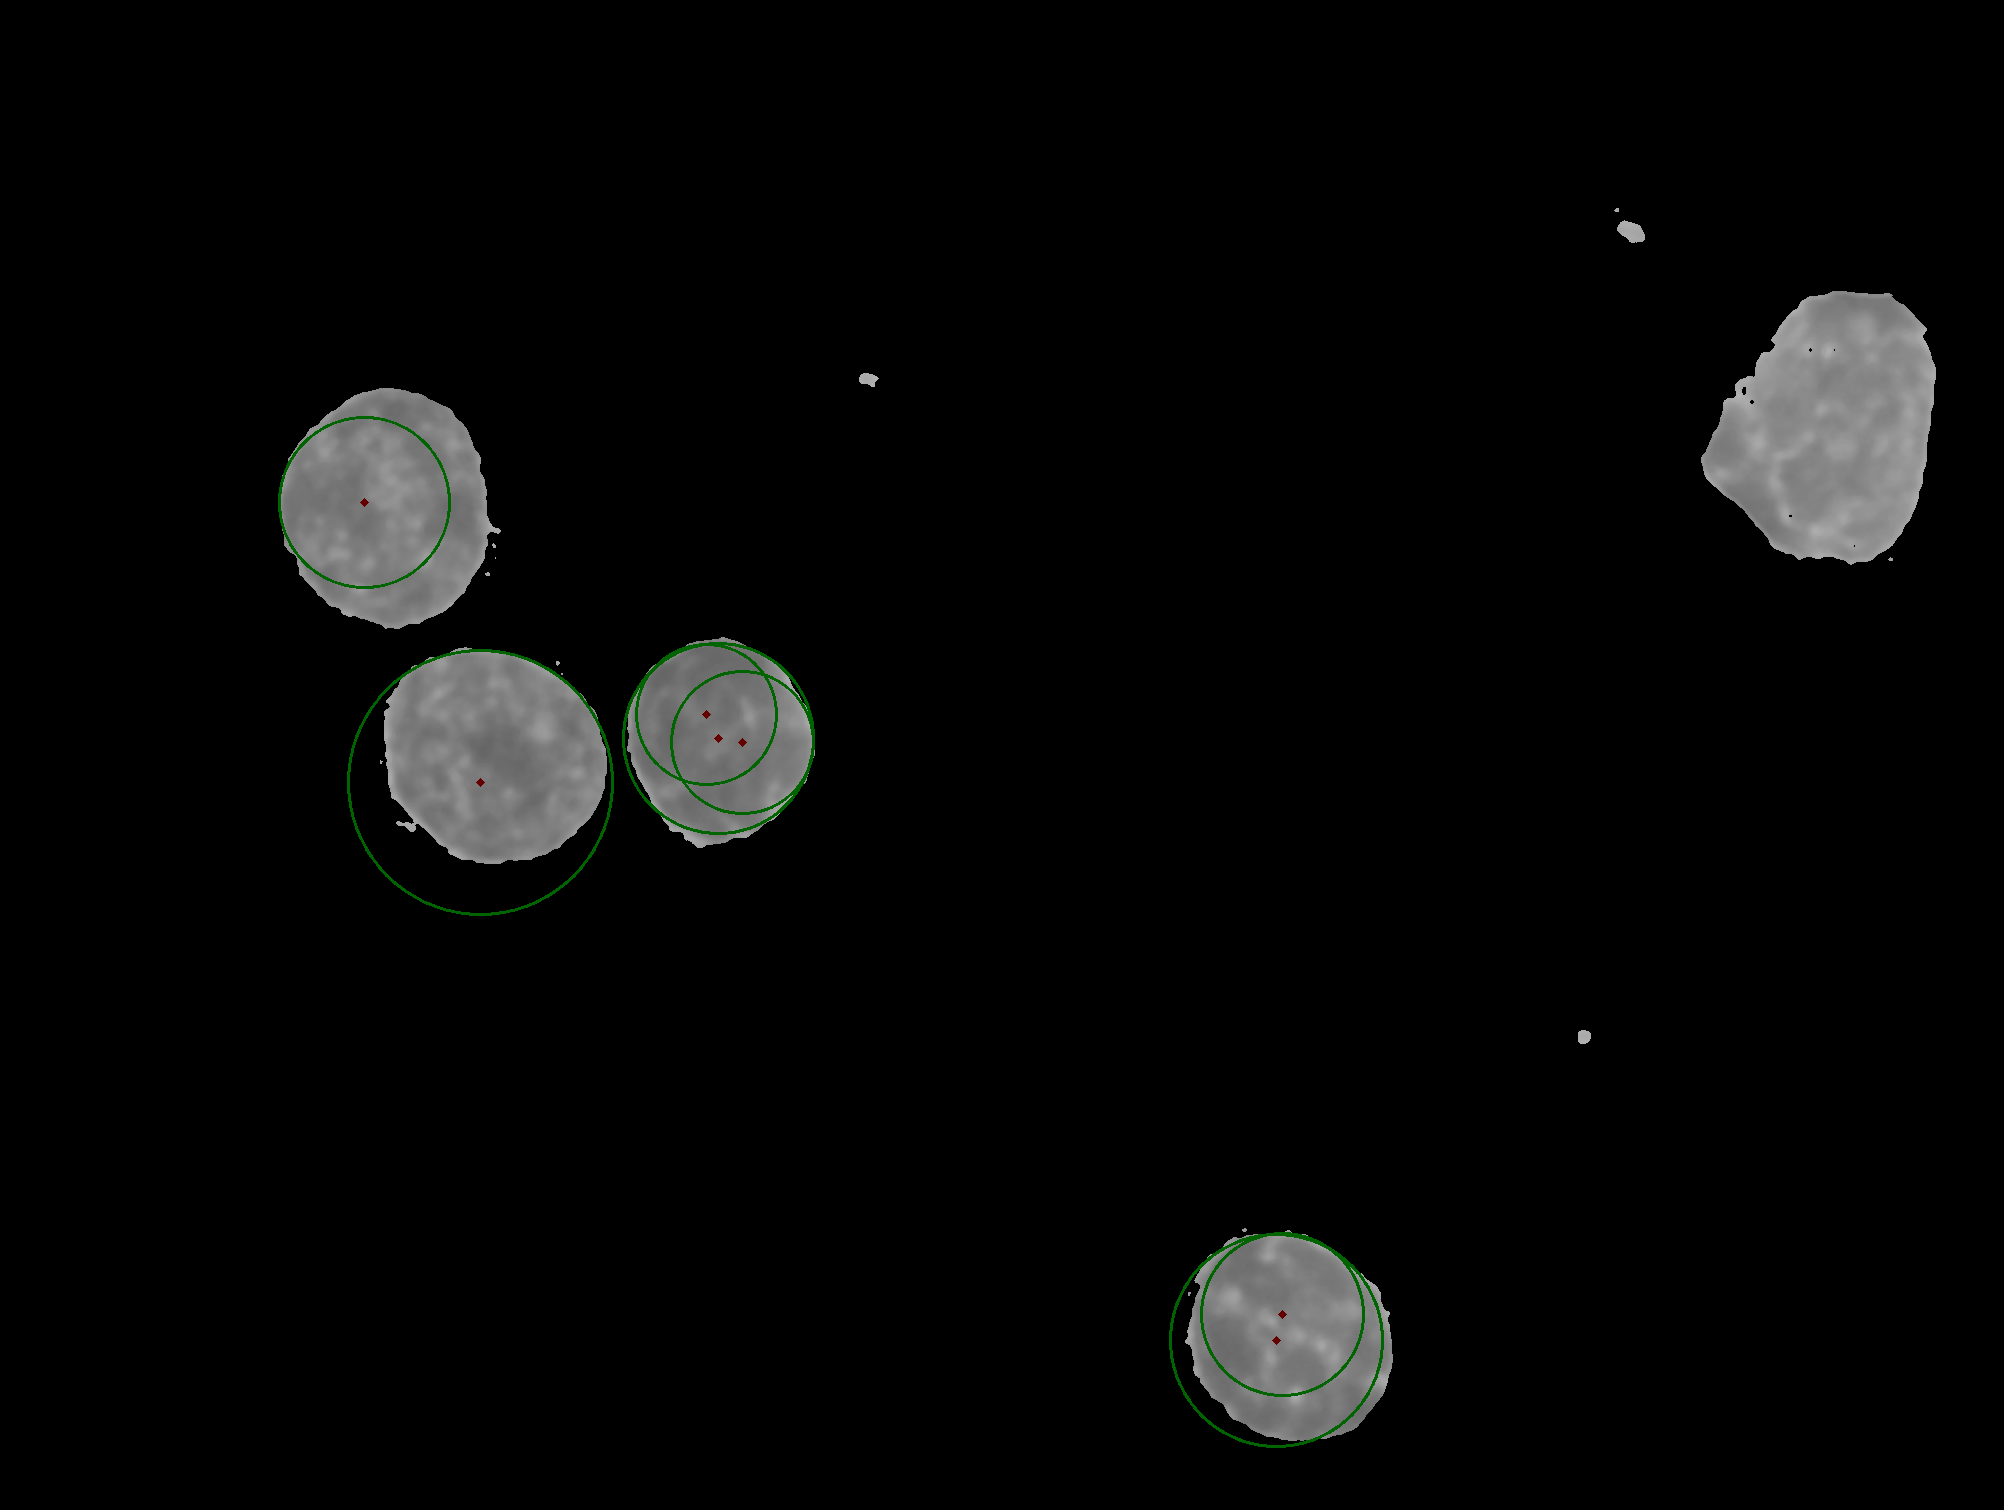

In [ ]:
# apply method on grayscale, blurred image with circles of radius between 40-100 pixels
circles = cv2.HoughCircles(gray_cells,cv2.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=30, maxRadius=220)
# for each detected circle, draw larger circle and apply to new image
circles = np.uint16(np.around(circles))
for  i in circles[0,:]:
  # draw the outer circle
  cv.circle(cimg,(i[0],i[1]),i[2],(0,100,0),2)
  # draw the center of the circle
  cv.circle(cimg,(i[0],i[1]),2,(0,0,100),3)
from google.colab.patches import cv2_imshow
cv2_imshow(cimg)

In [ ]:
import cv2
import matplotlib.pyplot as plt

# load and read the image
IMAGE_WIDTH = 280
IMAGE_HEIGHT = 200
image_orig = cv.imread('/content/drive/MyDrive/Leukemia_Image.jpg')


In [ ]:
# resizing and making a copy of original image
image_orig = cv2.resize(image_orig,(IMAGE_WIDTH, IMAGE_HEIGHT))
image = image_orig.copy()


In [ ]:
# Apply medianBlur and convert image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
img = cv2.medianBlur(gray_image, 5)

In [ ]:
# Apply image thresholding with source image, threshold value, maximum value, and method used
ret, th1 = cv2.threshold(img, 120, 200, cv2.THRESH_BINARY)

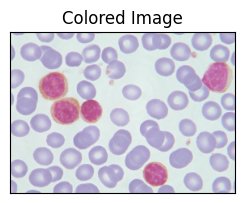

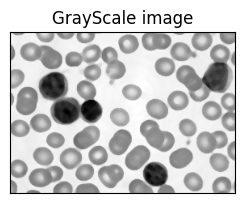

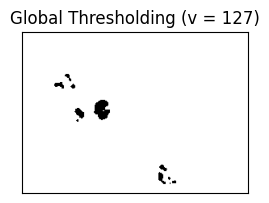

In [ ]:
# setting names for each image
titles = ['Colored Image', 'GrayScale image', 'Global Thresholding (v = 127)']
# setting list of images
image = [image_orig, img, th1]
# Adding details to show/label images
for i in range(3):
  plt.subplot(2, 2, i+1), plt.imshow(image[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
  # Displaying colored, GrayScale, and Thresholded image
  plt.show()
